## Correlation Between Age and Gender

*Impont Necessary Libraries*

In [466]:
import pandas as pd
import pingouin as pg
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
import statsmodels.formula.api as smf
from plotnine import *
import numpy as np
import altair as alt
from scipy import stats
import statsmodels.api as sm
from io import StringIO
from IPython.display import display, HTML
from IPython.display import display_markdown



*Load Data*
- Load data from *GPT2-large-dimensions.csv*

In [467]:
df = pd.read_csv('GPT2-large-dimensions.csv')
# df.head()

*Pearson Correlation*
- Compute the Pearson Correlation Coefficient between: 
    - age
    - gender

In [468]:
pearsons_output = pg.corr(df['age.main'], df['gender.main'], method='pearson')
# pearsons_output

*Style*
- Display with *display_markdown*

In [469]:
display_markdown(
    pearsons_output.to_markdown(),
    raw=True
)

|         |    n |        r | CI95%       |   p-val |   BF10 |   power |
|:--------|-----:|---------:|:------------|--------:|-------:|--------:|
| pearson | 3495 | 0.872559 | [0.86 0.88] |       0 |    inf |       1 |

<!-- *Style*
- Set uniform dark background
- Numeric formatting: for the variables *p-value* and *power* keep only one decimal 
- Set table custom style  -->

In [470]:
# styled = (
#     pearsons_output.style

#     .apply(lambda s: [
#         'background-color: #1e1e1e' for _ in range(len(s))
#     ], axis=0)

#     # numeric formatting
#     .format({
#         "p-val": "{:.1f}",
#         "power": "{:.1f}",
#     })

#     .set_table_styles([
#         # header
#         {"selector": "th",
#          "props": [
#              ("font-size", "16px"),
#              ("font-weight", "bold"),
#              ("padding", "8px"),
#              ("border", "1px solid #CCCCCC"),
#              ("background-color", "#1e1e1e"),
#              ("text-align", "right"),
#          ]},

#         # body
#         {"selector": "td",
#          "props": [
#              ("font-size", "17.5px"),
#              ("padding", "8px"),
#              ("border", "1px solid #CCCCCC"),
#              ("text-align", "left"),
#              ("white-space", "pre-wrap"),
#              ("max-width", "450px"),
#          ]},

#         # style index (pearson row label)
#         {"selector": "th.row_heading",
#          "props": [
#              ("font-size", "17.5px"),
#              ("font-weight", "normal"),
#              ("text-align", "left"),
#              ("padding-left", "10px"),
#          ]},
#     ])
# )

# styled


*Heatmap - Robutstness Check*
- Select three alternative measures for *age* and *gender* to evaluate robustness
- Pairwise Pearson Correlation Coefficients between the three different methods of extracting *age* and *gender*

In [471]:
age_cols = ['age.red', 'age.ext', 'age.main']
gender_cols = ['gender.red', 'gender.ext', 'gender.main']

# calculating pairwise correlations across age and gender extraction methonds
age_corr = df[age_cols].corr(method='pearson')
gender_corr = df[gender_cols].corr(method='pearson')

*Visualization*
- Individual Color Normalization
    - for each correlation matrix, the minimum and maximum correlation values are computed and used to define an individual color normalization range (vmin/vmax)
    - this ensures that color intensity accurately reflects variation within each matrix
- Heatmap
    - the build-in seaborn *cool–warm* color pallete was used
    - the color scale was centered at zero, so that stronger positive correlations are emphasized with warmer colors
    - by setting *center=0.0*, the color scale effectively suppresses the cool (blue) spectrum
    - cells were annotated with the exact correlation coefficients rounded to two decimals
    - the vmin/vmax normalization range was applied to control the mapping between correlation values and color intensity
    - grid lines and square cells were used to improve readability and ensure consistent visual structure across heatmaps

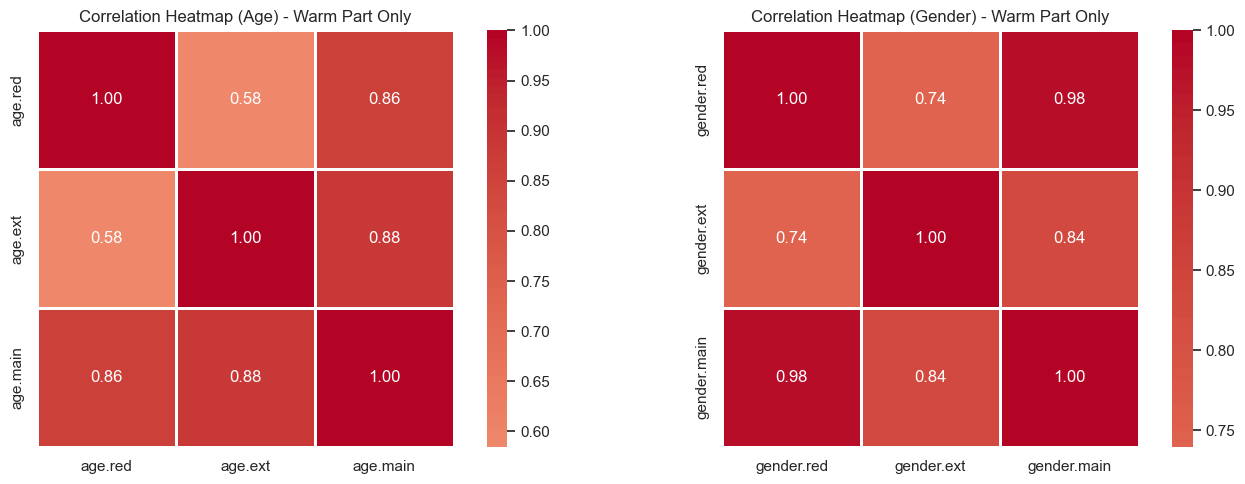

In [472]:
# find the absolute min/max across the entire matrix (including the 1.00 diagonal)
age_min = age_corr.min().min()
age_max = age_corr.max().max()
gender_min = gender_corr.min().min()
gender_max = gender_corr.max().max()

# normalization for age
age_norm = Normalize(vmin=age_min, vmax=age_max)

# normalization for gender
gender_norm = Normalize(vmin=gender_min, vmax=gender_max)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# settings for annotation and line style
annot_settings = {"color": 'white'}
line_style = {'linewidths': 0.75, 'linecolor': 'white'}

# Age Heatmap
sns.heatmap(
    age_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    norm=age_norm,
    center=0.0,
    square=True,
    ax=axes[0],
    cbar=True,
    **line_style,
    annot_kws=annot_settings
)
axes[0].set_title(f"Correlation Heatmap (Age) - Warm Part Only")

# Gender Heatmap
sns.heatmap(
    gender_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    norm=gender_norm,
    center=0.0,
    square=True,
    ax=axes[1],
    cbar=True,
    **line_style,
    annot_kws=annot_settings
)
axes[1].set_title(f"Correlation Heatmap (Gender) - Warm Part Only")

plt.tight_layout()

# png
plt.savefig(
    "correlation_heatmaps_age_gender.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Relationship between Age and Gender

*Load Data*
- Load data from *GPT2-large-dimensions.csv*
- Rename the columns to pythonic names
- Estimate an OLS regression with *age_norm_main* as the dependent variable and *gender_norm_main* as the independent variable

In [473]:
data = pd.read_csv('GPT2-large-dimensions.csv')

data = data.rename(columns={
    'age_norm.main': 'age_norm_main',
    'gender_norm.main': 'gender_norm_main'
})

model = smf.ols('age_norm_main ~ gender_norm_main', data=data)
results = model.fit()
results.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          age_norm_main   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                 1.114e+04
Date:                Sun, 21 Dec 2025   Prob (F-statistic):               0.00
Time:                        22:48:05   Log-Likelihood:                 5425.6
No. Observations:                3495   AIC:                        -1.085e+04
Df Residuals:                    3493   BIC:                        -1.083e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.0211      0.003     -6.510      0.000      -0.027      -0.015
gender_norm_main     0.7450      0.007    105.565      0.000       0.731       0.759
==============================================================================
Omnibus:                      829.901   Durbin-Watson:                   1.255
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4643.267
Skew:                           1.012   Prob(JB):                         0.00
Kurtosis:                       8.271   Cond. No.                         9.75
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

*Style*
- Extract the tables as lists of strings to keep the original formatting
    - defines a helper function to extract regression summary tables directly from the statsmodels output
    - accesses the *.data* attribute of each summary table, which contains the raw table values as strings
    - for tables that include a header row:
        - uses the first row as column names
        - uses the first column as the DataFrame index
    - for tables without a header row:
        - converts the entire table into a DataFrame
        - sets the first column as the index to preserve row labels
    - applies this function separately to:
        - the model summary table
        - the coefficient table
        - the diagnostics table
- Removes index names to avoid displaying non-informative row headings
- Formats tables using *na_rep=""* to hide empty cells without altering numeric precision
- Applies a uniform dark background color across all table cells for visual consistency
- Hides default column headers for non-coefficient tables to achieve a cleaner layout
- Styles table components individually:
    - headers
    - data cells
    - row labels
- Converts each styled table to HTML and combines them into a single output 

In [ ]:
# extract the tables as lists of strings to keep the original formatting
def get_raw_table(table_obj, has_header=False):
    data = table_obj.data  # This is the raw list of strings from statsmodels
    if has_header:
        return pd.DataFrame(data[1:], columns=data[0]).set_index(data[0][0])
    return pd.DataFrame(data).set_index(0)

# applies this function
tbl0 = get_raw_table(results.summary().tables[0])
tbl1 = get_raw_table(results.summary().tables[1], has_header=True)
tbl2 = get_raw_table(results.summary().tables[2])

def apply_dark_style(df, is_coef_table=False):
    df_clean = df.copy()
    df_clean.index.name = None # remove non-informative row headings
    
    styler = df_clean.style.format(na_rep="")
    
    # background
    styler = styler.apply(lambda s: ['background-color: #1e1e1e' for _ in range(len(s))], axis=0)
    
    # hide column headers for Tables 0 and 2
    if not is_coef_table:
        styler = styler.hide(axis='columns')
    
    return styler.set_table_styles([
       # headers 
        {"selector": "th", "props": [("font-size", "16px"), ("font-weight", "bold"), ("padding", "8px"), 
                                     ("border", "1px solid #CCCCCC"), ("background-color", "#1e1e1e"), 
                                     ("color", "white"), ("text-align", "center")]},
        
        # data cells
        {"selector": "td", "props": [("font-size", "17.5px"), ("padding", "8px"), ("border", "1px solid #CCCCCC"), 
                                     ("color", "white"), ("text-align", "left")]},
        
        # row labels
        {"selector": "th.row_heading", "props": [("font-size", "17.5px"), ("font-weight", "normal"), 
                                                 ("color", "white"), ("text-align", "center")]}
    ])

# Title HTML
title_html = """
<h2 style="
   
    color: white;
    background-color: #1e1e1e;
   

">
    OLS Regression Results
</h2>
"""

# combine and display
full_html = (
    title_html +
    apply_dark_style(tbl0).to_html() + 
    apply_dark_style(tbl1, is_coef_table=True).to_html() + 
    apply_dark_style(tbl2).to_html()
)

display(HTML(full_html))

*Report the results of the model*
- Model Variables: 
    - Dependent Variable: *age_norm_main*
    - Independent Variable: *gender_norm_main*
- Results:
    - $R^{2}$ = 0.761 → indicates that 76.1% of the variance in normalized age is explained by normalized gender, suggesting a strong model fit
    - Adj. R-squared = 0.761 → accounts for the number of predictors and confirms that the explained variance remains unchanged, as the model includes a single predictor
    - F-statistic = 1.114e+04 → $1.114 \times 10^{4}$, p < 0.001 → assesses the overall significance of the regression model
    - Coefficient = 0.7450 → a one-unit increase in normalized gender is associated with a 0.745-unit increase in normalized age
    - Standard Error = 0.007 → indicates high precision in the estimated coefficient
    - t = 105.565, p < 0.001 → shows that the relationship between normalized gender and normalized age is highly statistically significant
    - P-value = 0.000 < 0.001 →  provides extremely strong evidence against the null hypothesis that the coefficient is zero (i.e., the independent variable has no effect on the dependent variable)
    - No. Observations = 3495
- Reporting the Relationship between Age and Gender: 
    - To examine the relationship between age and gender, we estimated an  OLS (Ordinary Least Squares) regression model with *age_norm_main* as the dependent variable and *gender_norm_main* as the independent variable. The analysis revealed a strong and statistically significant association between normalized gender and normalized age. The model explained a substantial proportion of the variance in normalized age ($R^{2}$ = 0.761; adjusted $R^{2}$ = 0.761), indicating a strong model fit. The overall regression was statistically significant (F = $1.114 \times 10^{4}$, p < 0.001).
    - Normalized gender was a significant positive predictor of normalized age (coef = 0.745, SE = 0.007, t = 105.565, p < 0.001), indicating that a one-unit increase in normalized gender is associated with a 0.745-unit increase in normalized age. The very small p-value provides extremely strong evidence against the null hypothesis that the regression coefficient equals zero. The analysis was based on 3,495 observations.


*Plot*
- Load data from *GPT2-large-dimensions.csv*
- Rename the columns to pythonic names
- Define highlighted social categories
- Separates the dataset into:
    - highlighted young / female categories
    - highlighted old / male categories
    - non-highlighted (background) categories
- Create a boolean mask identifying all highlighted categories; invert the mask to select all remaining (non-highlighted) observations for background plotting
- Estimate the linear relationship between normalized gender and normalized age using a fitted regression line
- Compute predicted values on the regression line for highlighted categories
- Prepare label placement by offsetting labels perpendicular to the regression line to avoid overlap
- Create the ggplot visualization:
    - Plot the regression line
    - Display background categories as hollow points
    - Highlight selected categories with distinct colors
    - Add connector lines and text labels
    - Customize axes, limits, and theme for clarity

c:\Users\30694\anaconda3\Lib\site-packages\plotnine\ggplot.py:623: PlotnineWarning: Saving 8 x 7 in image.
c:\Users\30694\anaconda3\Lib\site-packages\plotnine\ggplot.py:624: PlotnineWarning: Filename: regression_plot.png


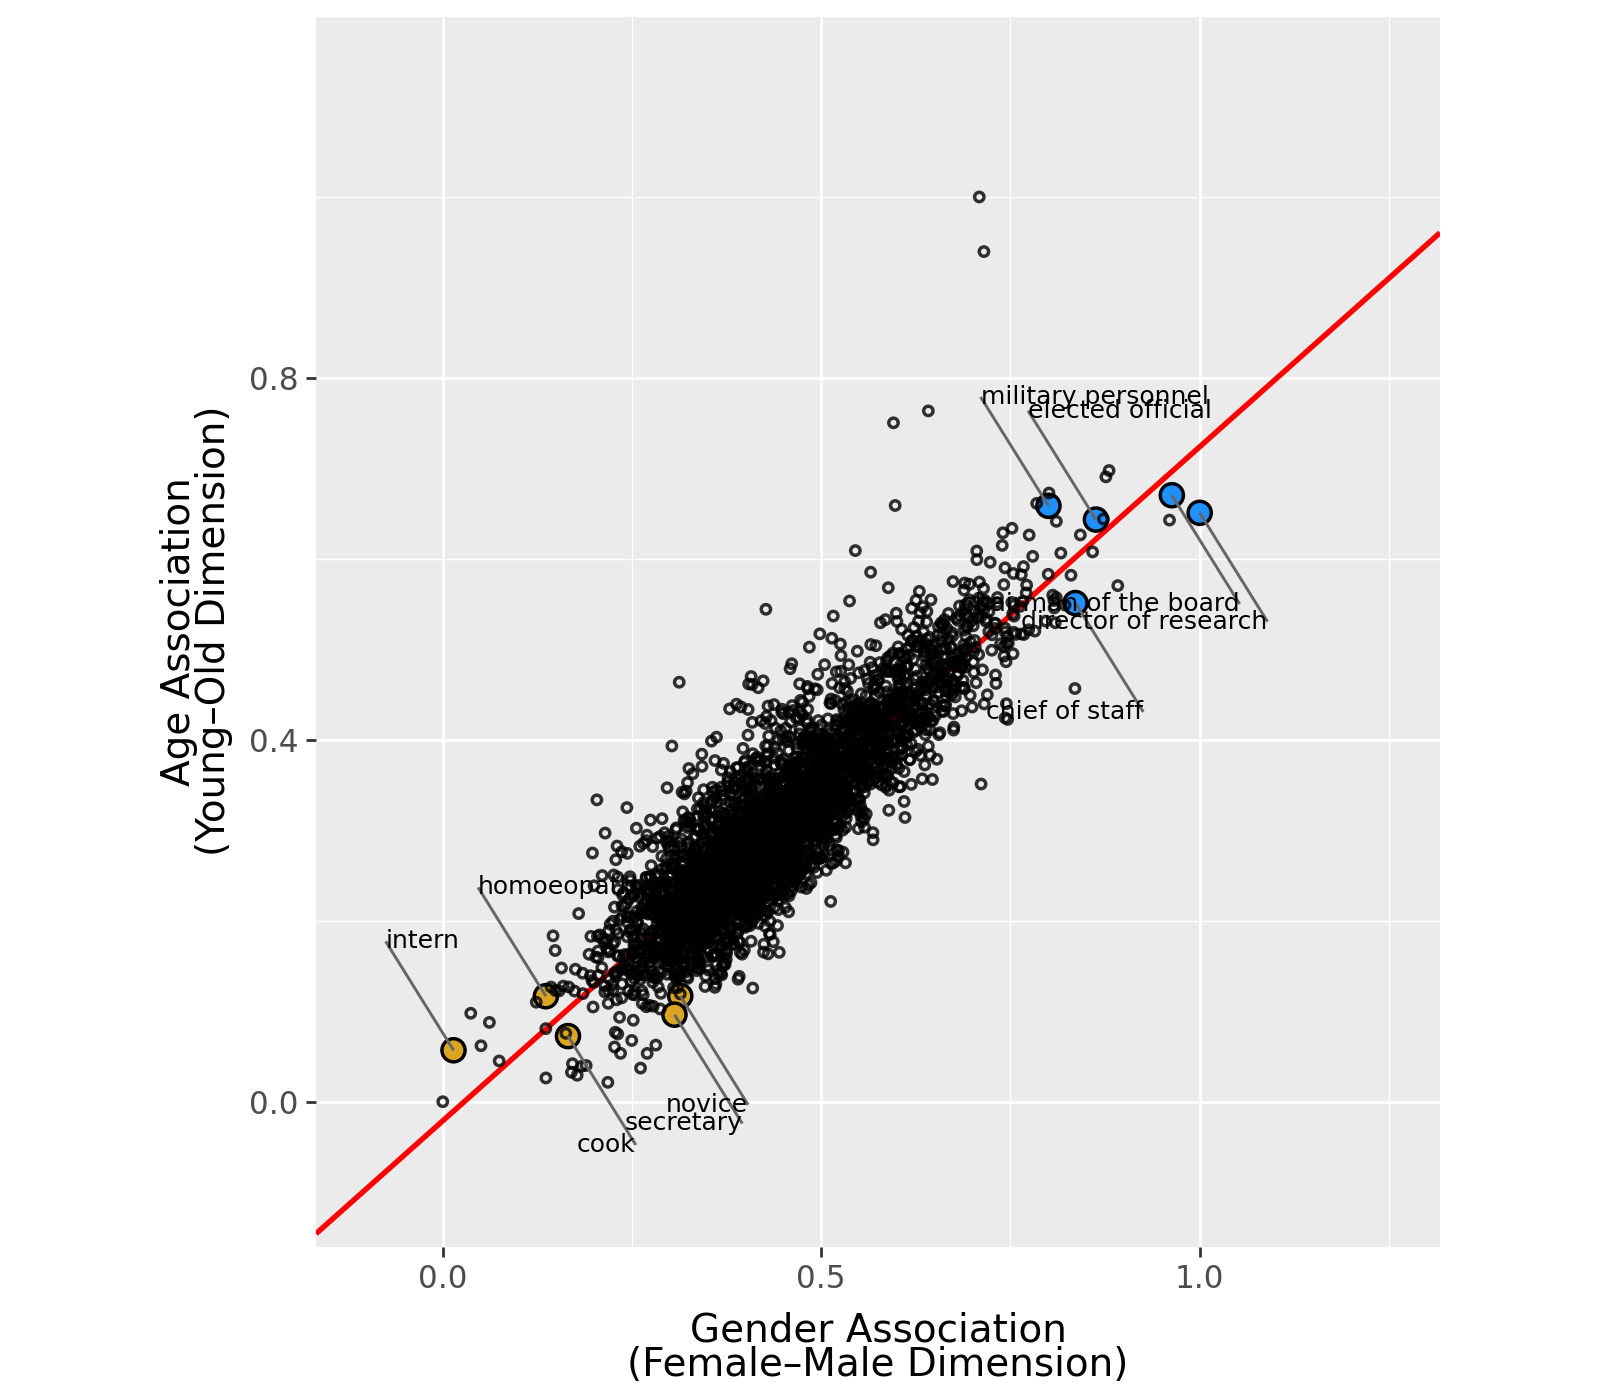

In [ ]:
data = pd.read_csv('GPT2-large-dimensions.csv')

data = data.rename(columns={
    'age_norm.main': 'age_norm_main',
    'gender_norm.main': 'gender_norm_main',
    'Social.Category' : 'Social_Category'
})

young_female = [
    "intern",
    "cook",
    "secretary",
    "novice",
    "homoeopath"
]

old_male = [
    "military personnel",
    "elected official",
    "chief of staff",
    "director of research",
    "chairman of the board"
]

df_young = data[data["Social_Category"].isin(young_female)]
df_old = data[data["Social_Category"].isin(old_male)]

# create a mask for all highlighted categories
highlighted_categories = young_female + old_male

# create the mask (True for highlighted, False for others)
highlighted_mask = data["Social_Category"].isin(highlighted_categories)

# use the not operator (~) to select rows that are not highlighted
df_others = data[~highlighted_mask]

coef = np.polyfit(
    data["gender_norm_main"],
    data["age_norm_main"],
    1
)

slope = coef[0]
intercept = coef[1]

# combine highlighted points
df_lbl = pd.concat([df_young, df_old]).copy()

# predicted y on the regression line
df_lbl["y_hat"] = slope * df_lbl["gender_norm_main"] + intercept

# side = +1 if point is above the line, -1 if below
df_lbl["side"] = np.where(
    df_lbl["age_norm_main"] >= df_lbl["y_hat"],
    1,
    -1
)

# normal vector to the regression line (perpendicular direction)
norm = np.sqrt(slope**2 + 1)
nx = -slope / norm
ny =  1.0   / norm

offset = 0.15   # tune distance from the line

# move labels away from the line, perpendicular to it
df_lbl["x_label"] = df_lbl["gender_norm_main"] + df_lbl["side"] * offset * nx
df_lbl["y_label"] = df_lbl["age_norm_main"]   + df_lbl["side"] * offset * ny

# horizontal alignment so text points back toward the dot
df_lbl["ha"] = np.where(df_lbl["side"] == 1, "left", "right")

p = (
    ggplot(data, aes(x="gender_norm_main", y="age_norm_main"))

    + geom_abline(
        slope=slope,
        intercept=intercept,
        color="red",
        size=1.1
    )

    # highlighted young / female
    + geom_point(
        df_young,
        aes(x="gender_norm_main", y="age_norm_main"),
        size=4,
        stroke=0.7,
        fill="goldenrod",
        color="black"
    )

    # highlighted old / male
    + geom_point(
        df_old,
        aes(x="gender_norm_main", y="age_norm_main"),
        size=4,
        stroke=0.7,
        fill="dodgerblue",
        color="black"
    )

    # background points — hollow black
    + geom_point(
        df_others,
        size=1.2,
        stroke=0.7,
        fill="none",
        color="black",
        alpha=0.8
    )

    # connector lines (from dot to label)
    + geom_segment(
        df_lbl,
        aes(
            x="gender_norm_main",
            y="age_norm_main",
            xend="x_label",
            yend="y_label"
        ),
        color="#666666",
        size=0.6
    )

    # labels
    + geom_text(
        df_lbl,
        aes(
            x="x_label",
            y="y_label",
            label="Social_Category",
            ha="ha"
        ),
        size=9
    )

    # axis labels
    + labs(
        x="Gender Association\n(Female–Male Dimension)",
        y="Age Association\n(Young–Old Dimension)"
    )

    # match ggplot theme & spacing
    + theme_gray(base_size=14)
    + theme(
        figure_size=(8, 7),

        plot_margin_right = 0.1, 
        plot_margin_left = 0.1,

        panel_grid_minor=element_line(color="white"),
        panel_grid_major=element_line(color="white")
    )

    # fixed aspect ratio
    + coord_cartesian(
        xlim=(-0.1, 1.25),
        ylim=(-0.1, 1.1)
    )

    + scale_x_continuous(
        breaks=[0.0, 0.5, 1.0],
        minor_breaks=[0.0, 0.25, 0.5, 0.75, 1.0, 1.25]
    )

    + scale_y_continuous(
            breaks=[0.0, 0.4, 0.8],
            minor_breaks=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
        )
)

p.save('regression_plot.png', dpi=300)

p


*Interactive Plot*
- Define highlighted social categories
- Prepare data for interactive visualization
    - creates a copy of the dataset for use with Altair
    - assigns each observation to a categorical group (young_female, old_male, other)
    - stores group membership in a new variable used for visual encoding
- Create the interactive scatter plot
    - plot normalized gender against normalized age
    - use color, size, and opacity to distinguish highlighted and background categories
    - add interactive tooltips displaying category and association scores
- Add a fitted linear regression line as a visual reference
- Customize axes and layout
    - fix axis ranges and tick spacing
    - apply grid lines and remove the default chart border

In [ ]:
# highlighted categories
young_female = [
    "intern",
    "cook",
    "secretary",
    "novice",
    "homoeopath"
]

old_male = [
    "military personnel",
    "elected official",
    "chief of staff",
    "director of research",
    "chairman of the board"
]

highlighted_categories = young_female + old_male

# prepare data for Altair
data_alt = data.copy()

def assign_group(cat):
    if cat in young_female:
        return "young_female"
    elif cat in old_male:
        return "old_male"
    else:
        return "other"

data_alt["group"] = data_alt["Social_Category"].apply(assign_group)

# Scatter plot (interactive)
points = (
    alt.Chart(data_alt)
    .mark_circle(
        # size=45, 
        stroke="black",
        strokeWidth=0.5,
        strokeOpacity=0.8
    )
    .encode(
       x=alt.X(
            "gender_norm_main:Q",
            title="Gender Association (Female–Male Dimension)",
            scale=alt.Scale(domain=[0.0, 1.0]),
            axis=alt.Axis(
                values=[i / 10 for i in range(0, 11)],  # 0.0 → 1.0 step 0.1
                format=".1f"
            )
        ),
        y=alt.Y(
            "age_norm_main:Q",
            title="Age Association (Young–Old Dimension)",
            scale=alt.Scale(domain=[0.0, 1.0]),
            axis=alt.Axis(
                values=[i / 10 for i in range(0, 11)],  # 0.0 → 1.0 step 0.1
                format=".1f"
            )
        ),
        fill=alt.Fill(
            "group:N",
            scale=alt.Scale(
                domain=["young_female", "old_male", "other"],
                range=["goldenrod", "dodgerblue", "#d9d9d9"]
            ),
            legend=None
        ),
         size=alt.condition(
            alt.datum.group != "other",
            alt.value(150),   # highlighted
            alt.value(40)    # background
        ),
        opacity=alt.condition(
            alt.datum.group == "other",
            alt.value(0.7),
            alt.value(1.0)
        ),
        tooltip=[
            alt.Tooltip("Social_Category:N", title="Category"),
            alt.Tooltip("gender_norm_main:Q", title="Gender assoc.", format=".2f"),
            alt.Tooltip("age_norm_main:Q", title="Age assoc.", format=".2f"),
        ]
    )
)

# Regression line (OLS)
regression = (
    alt.Chart(data_alt)
    .transform_regression(
        "gender_norm_main",
        "age_norm_main",
        method="linear"
    )
    .mark_line(color="red", size=2)
    .encode(
        x="gender_norm_main:Q",
        y="age_norm_main:Q"
    )
)

# Combine & style
chart = (
    (points + regression)
    .properties(
        width=600,
        height=600
    )
    .configure_axis(
        grid=True,
        gridColor="#e5e5e5",
        labelFontSize=12,
        titleFontSize=13
    )
    .configure_view(
        stroke=None
    )
)

chart

alt.LayerChart(...)

##### Reflecting on the Outliers: Why these specific points?
The researchers specifically selected these outliers because they verify the historical bias explored in the paper: the cultural tendency to associate younger women with entry-level or "non-core" roles, while older men are linked to high-status, high-earning positions. A major reason for these outliers is that as women get older, they have historically tended to disappear from media and public records.

By highlighting these specific points, the study demonstrates how visual data acts as a repeater for these stereotypes. The authors focused on these examples because they represent the potent stereotypes. They intentionally omitted the outliers that suggested the opposite, such as colonel, old women e.c.t, as those points do not represent the systemic historical bias.

## Amplification via Google Search

*Load Data*
- Load experimental datasets
    - control condition data from *experiment_control.csv*
    - treatment condition data from *experiment_treatment.csv*
- Compute the mean estimated age for each category in the control condition
- Merge control category means into the treatment dataset 
- Compute the age difference between treatment estimates and control means
- Create a copy of the subset with relevant columns *age_difference, gender, category*
- Retain only observations labeled as *Female* or *Male*, excluding *Not sure* responses
- Count observations by gender to verify filtering

In [ ]:
control = pd.read_csv("experiment_control.csv")
treatment = pd.read_csv("experiment_treatment.csv")

# mean for each category in control
control_mean = (
    control
    .groupby("category", as_index=False)
    .agg(control_mean_age=("age", "mean"))
)

treatment_merged = treatment.merge(
    control_mean,
    on="category",
    how="left"
)

# age difference
treatment_merged["age_difference"] = treatment_merged["age"] - treatment_merged["control_mean_age"] 

treatment_merged_plot = treatment_merged[
    ["age_difference", "gender", "category"]
].copy()

# drop not sure answers
treatment_merged_plot = treatment_merged_plot[
    treatment_merged_plot["gender"].isin(["Female", "Male"])
]

treatment_merged_plot["gender"].value_counts(dropna=False)
# treatment_merged_plot["age_difference"].describe()



gender
Female    2589
Male      2240
Name: count, dtype: int64

*Plotting*
- Compute mean age differences by gender
- Create a density plot of age differences
- Add reference lines
- Customize colors and aesthetics
- Configure axes and labels
- Apply theme and layout settings


Note: Fixed x-axis limits are used via *scale_x_continuous(limits=(-22, 30))* rather than *trim=TRUE* in geom_density, because trimming stops the density curve at the minimum and maximum observed values.

c:\Users\30694\anaconda3\Lib\site-packages\plotnine\ggplot.py:623: PlotnineWarning: Saving 8 x 6 in image.
c:\Users\30694\anaconda3\Lib\site-packages\plotnine\ggplot.py:624: PlotnineWarning: Filename: Amplification_via_Google_Search.png
c:\Users\30694\anaconda3\Lib\site-packages\plotnine\layer.py:293: PlotnineWarning: stat_density : Removed 44 rows containing non-finite values.
c:\Users\30694\anaconda3\Lib\site-packages\plotnine\layer.py:293: PlotnineWarning: stat_density : Removed 44 rows containing non-finite values.


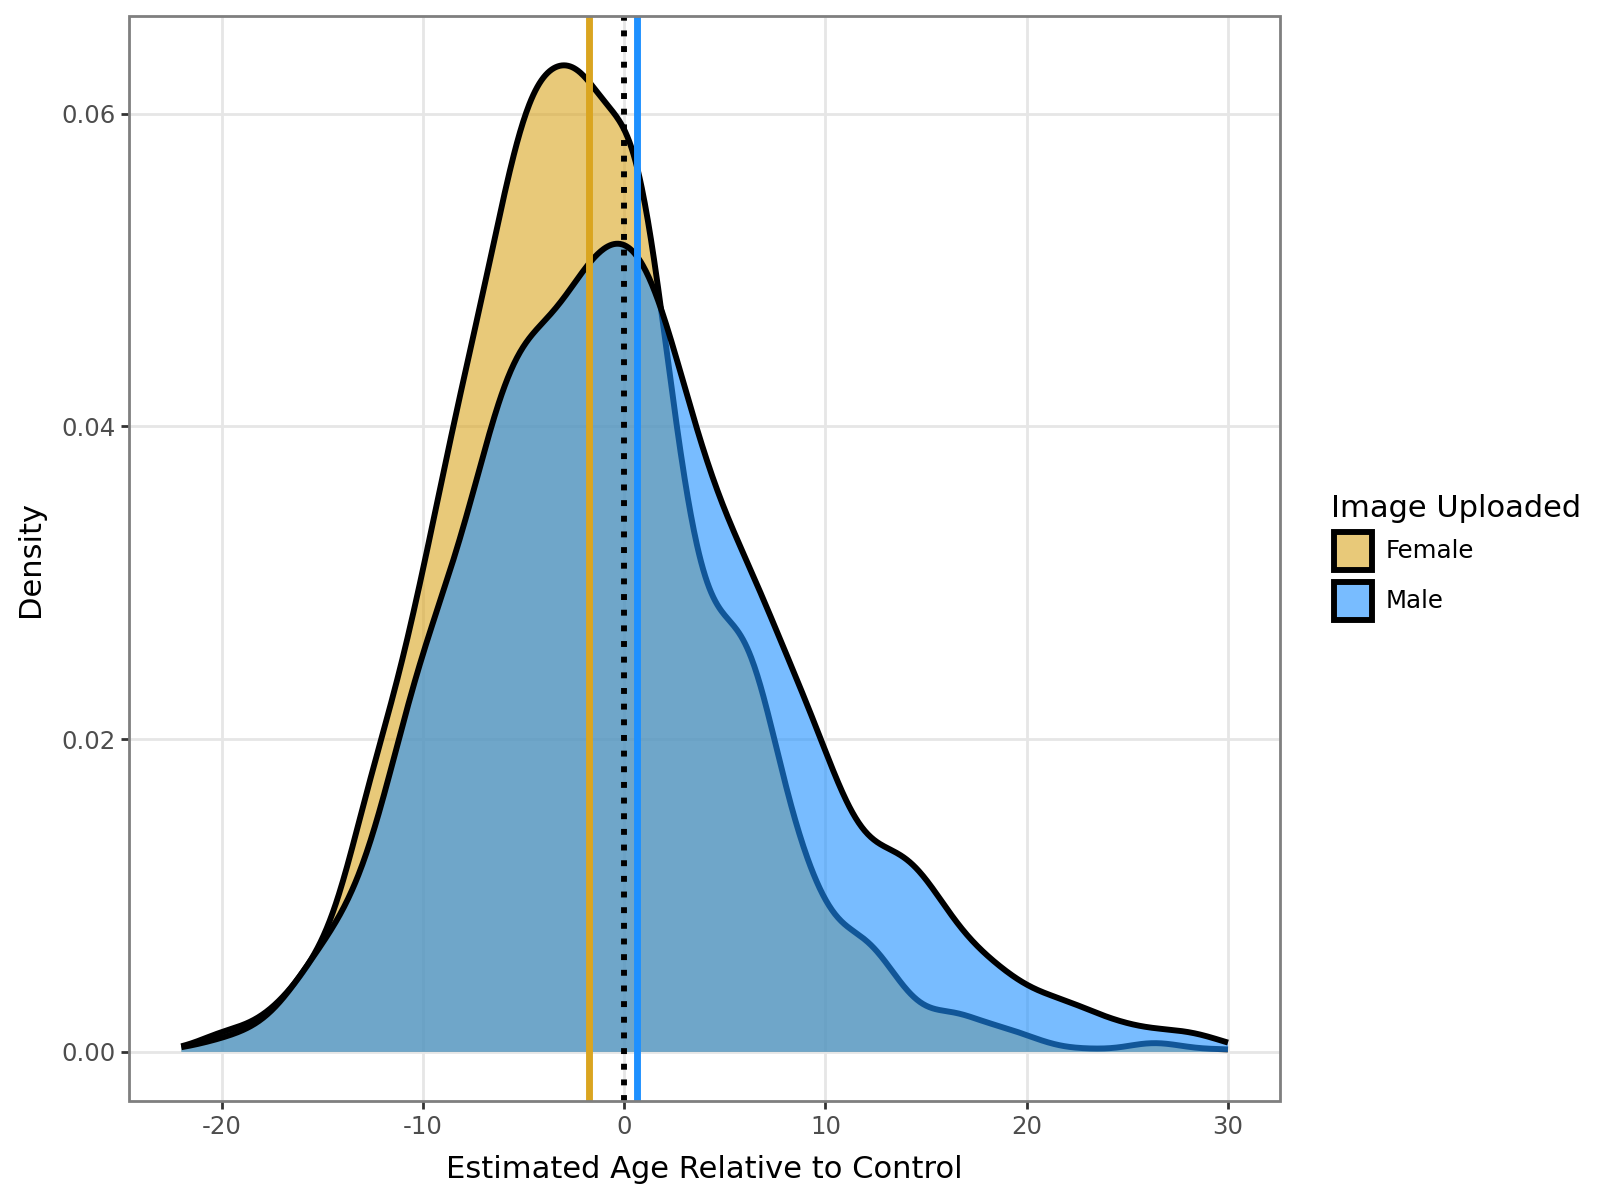

In [ ]:
# means by gender
mean_lines = (
    treatment_merged_plot
    .groupby("gender", as_index=False)
    .agg(mean_age_diff=("age_difference", "mean"))
)

p = (
    ggplot(
        treatment_merged_plot,
        aes(x="age_difference", fill="gender")
    )

    # density curves
    + geom_density(
        alpha=0.6,
        size=1.2,
        color="black",
    )

    # zero reference line
    + geom_vline(
        xintercept=0,
        linetype="dotted",
        size=1.2,
        color="black"
    )

    # mean lines
    + geom_vline(
        mean_lines,
        aes(xintercept="mean_age_diff", color="gender"),
        size=1.4
    )

    # fill colors
    + scale_fill_manual(
        values={
            "Female": "goldenrod",
            "Male": "dodgerblue"
        }
    )

    # line colors
    + scale_color_manual(
        values={
            "Female": "goldenrod",
            "Male": "dodgerblue"
        },
        guide=None
    )

    # axis limits 
    + scale_x_continuous(
        limits=(-22, 30)
    )

    # labels
    + labs(
        x="Estimated Age Relative to Control",
        y="Density",
        fill="Image Uploaded"
    )

    # theme
    + theme_bw()
    + theme(
        figure_size=(8, 6),
        legend_position="right",
        panel_grid_major=element_line(color="#e6e6e6"),
        panel_grid_minor=element_blank()
    )
)

p.save('Amplification_via_Google_Search.png', dpi=300)
p


*T-tests*

Important: the paper is written in R so the p-value is different cause python has smaller numbers than R

- Women are younger than men: Women vs Man
    - Retain only observations labeled as *Female* or *Male*, excluding *Not sure* responses
    - Compute mean age estimates by gender
    - Compute gender difference in estimated age

In [ ]:
treatment_ttest = treatment_merged.copy()

# drop not sure
treatment_ttest = treatment_ttest[treatment_ttest["gender"].isin(["Female", "Male"])].copy()

# split genders and find the means
female_mean_age = treatment_ttest.loc[
    treatment_ttest["gender"] == "Female", "age"
].mean()

male_mean_age = treatment_ttest.loc[
    treatment_ttest["gender"] == "Male", "age"
].mean()

gender_difference = female_mean_age - male_mean_age
# gender_difference

print("Gender difference =", round(gender_difference, 2))


Gender difference = -5.46


Explanation: The gender difference in estimated age is -5.46 (Female − Male), indicating that Female images are estimated to be younger than Male images.

- Split the treatment database by gender
- Perform a two-sample t-test comparing mean age estimates between Female and Male groups
- Use Welch’s t-test *equal_var = False* to avoid assuming equal variances between groups

In [ ]:
female = treatment_ttest.loc[
    treatment_ttest["gender"] == "Female",
    "age"
]

male = treatment_ttest.loc[
    treatment_ttest["gender"] == "Male",
    "age"
]

t_statistic, p_value = stats.ttest_ind(female, male, equal_var=False)

print("t-statistic =", round(t_statistic, 2)," p-value =", p_value)

t-statistic = -19.07  p-value = 5.240475629525052e-78


Explanation: Welch’s t-test comparing mean estimated age between Female and Male images. The output of the test is: t-statistic = -19.07 & p-value = 5.240475629525052e-78 < 0.01, indicating a statistically significant difference in mean estimated age between the two groups

- Women's image --> lower age for each occupation : Women vs Control

In [ ]:
treatment_ttest_w = treatment_merged.copy()

# drop not sure and man
treatment_ttest_w = treatment_ttest_w[treatment_ttest_w["gender"].isin(["Female"])].copy()

female_mean_age = treatment_ttest_w["age"].mean()

female_control_mean_age = treatment_ttest_w["control_mean_age"].mean()

female_difference = female_mean_age - female_control_mean_age
# female_difference

print("Female difference =", round(female_difference, 2))

Female difference = -1.75


Explanation: The difference in estimated age for female subjects is -1.75(Treatment − Control), indicating that when images are used, women are estimated to be younger than they are in the control group.

In [ ]:
female_diff = (
    treatment_ttest_w["age"] -
    treatment_ttest_w["control_mean_age"]
)

t_statistic, p_value = stats.ttest_1samp(female_diff, popmean=0) 

print("t-statistic =", round(t_statistic, 2)," p-value =", p_value)

t-statistic = -11.32  p-value = 4.8184762096227717e-29


Explanation: A One-Sample t-test was conducted on the difference scores (Treatment − Control) for Female to determine if the age estimation shift was significant. The test compared the mean difference against a null hypothesis of 0 ($popmean=0$). The results ($t = -11.32$, $p = 4.8184762096227717e-29 < 0.01$) indicate a statistically significant downward shift, confirming that the use of images causes women to be estimated as significantly younger than the control baseline.

- Men's image --> highter age for each occupation : Men vs Control

In [ ]:
treatment_ttest_m = treatment_merged.copy()

# drop not sure and man
treatment_ttest_m = treatment_ttest_m[treatment_ttest_m["gender"].isin(["Male"])].copy()

male_mean_age = treatment_ttest_m["age"].mean()

male_control_mean_age = treatment_ttest_m["control_mean_age"].mean()

male_difference = male_mean_age - male_control_mean_age
# male_difference

print("Male difference =", round(male_difference, 2))

Male difference = 0.64


Explanation: The difference in estimated age for male subjects is 0.64(Treatment − Control)indicating that when images are used, men are estimated to be older than they are in the control group.

In [ ]:
male_diff = (
    treatment_ttest_m["age"] -
    treatment_ttest_m["control_mean_age"]
)


t_statistic, p_value = stats.ttest_1samp(male_diff, popmean=0) 

print("t-statistic =", round(t_statistic, 2)," p-value =", p_value)

t-statistic = 3.42  p-value = 0.0006373900146625942


Explanation: A One-Sample t-test was conducted on the difference scores (Treatment − Control) for Male to determine if the age estimation shift was significant. The test compared the mean difference against a null hypothesis of 0 ($popmean=0$). The results ($t = 3.42$, $p = 0.0006373900146625942 < 0.01$) indicate a statistically significant upward shift. This confirms that the introduction of images causes a significant overestimation of age for men compared to the control baseline.

## Investigate the Amplification

- Combine dataset: 
    - Concatenate the treatment and control datasets row-wise
- Select relevant variables: *subj, category, age, gender, condition*
- Retain only observations labeled as Female or Male

In [ ]:
# read control, treatment earlier
# treatment.columns, control.columns

combine = pd.concat([treatment, control],
                      axis=0,
                      ignore_index=True)

combine = combine[
    ["subj", "category", "age", "gender", "condition"]
]

# drop not sure 
combine = combine[combine["gender"].isin(["Female","Male"])].copy()
# combine

- Specify the regression model formula: 
    - dependent variable: age
    - independent variables: condition*gender, category, subj
        - use Treatment coding for categorical variables:
            - *Control* as the reference level for *condition*
            - *Male* as the reference level for *gender*
- Estimate the regression model

In [ ]:
formula = (
    "age ~ "
    "C(condition, Treatment('Control')) * "
    "C(gender, Treatment('Male')) "
    "+ category + subj"
)

model_multi = smf.ols(formula, data=combine)
age_regression = model_multi.fit()
age_regression.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    age   R-squared:                       0.586
Model:                            OLS   Adj. R-squared:                  0.560
Method:                 Least Squares   F-statistic:                     22.30
Date:                Sun, 21 Dec 2025   Prob (F-statistic):               0.00
Time:                        22:45:05   Log-Likelihood:                -28066.
No. Observations:                8514   AIC:                         5.715e+04
Df Residuals:                    8005   BIC:                         6.074e+04
Df Model:                         508                                         
Covariance Type:            nonrobust                                         
======================================================================================================================================================
                                                                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                             44.1459      1.524     28.963      0.000      41.158      47.134
C(condition, Treatment('Control'))[T.Image]                                           -4.7819      1.447     -3.305      0.001      -7.618      -1.946
C(gender, Treatment('Male'))[T.Female]                                                -2.1919      0.288     -7.614      0.000      -2.756      -1.628
category[T.appliedscientist]                                                          -0.1997      0.772     -0.259      0.796      -1.713       1.314
category[T.artstudent]                                                               -15.9195      0.769    -20.691      0.000     -17.428     -14.411
category[T.artteacher]                                                                -1.5589      0.760     -2.050      0.040      -3.049      -0.068
category[T.astronaut]                                                                  0.8480      0.756      1.121      0.262      -0.635       2.331
category[T.astrophysicist]                                                             5.5395      0.746      7.422      0.000       4.076       7.002
category[T.automotiveengineer]                                                        -3.0039      0.741     -4.056      0.000      -4.456      -1.552
category[T.bookkeeper]                                                                -0.1153      0.754     -0.153      0.878      -1.593       1.362
category[T.cardiologist]                                                               7.2159      0.752      9.600      0.000       5.743       8.689
category[T.chiefexecutiveofficer]                                                     10.7181      0.744     14.401      0.000       9.259      12.177
category[T.chiropractor]                                                               0.8699      0.749      1.161      0.246      -0.599       2.338
category[T.clarinetist]                                                               -3.6484      0.738     -4.943      0.000      -5.095      -2.202
category[T.climatologist]                                                              1.0234      0.759      1.348      0.178      -0.465       2.511
category[T.computerexpert]                                                            -5.7173      0.738     -7.751      0.000      -7.163      -4.271
category[T.cosmeticsurgeon]                                                            4.5735      0.752      6.085      0.000       3.100       6.047
category[T.dietician]                                          

Explanation: 
- Intercept: is the baseline age estimate
- C(condition, Treatment('Control'))[T.Image]: shows that for Males (ref level) seeing an image reduces the age estimate by approximately 4.78 years, this effect is highly significant because p-value = 0.001 < 0.01
- C(gender, Treatment('Male'))[T.Female]: shows that in the Control condition, Females are perceived as 2.19 years younger than males, this is highly significant because p-value = 0.00 < 0.01, confirming a baseline gender stereotype\
- C(condition, Treatment('Control'))[T.Image]:C(gender, Treatment('Male'))[T.Female]: shows the amplification effect, for Females, the youthfulness bias increases by an additional 0.8495 years when seeing an image, compared to the change seen in males, with a p-value of 0.007 < 0.01, this interaction is statistically significant

- Regression Model with:
    - dependent variable: age
    - independent variables: category, subj
- Estimate the regression model

In [ ]:
model_age_c_s = smf.ols(
    "age ~ category + subj",
    data=combine
)
new_reg = model_age_c_s.fit()
# new_reg.summary()

- Create a new column *age_pred* containing model-based predicted age values
- Create a new column *residual* containing residuals, computed as the difference between observed age and predicted age


In [ ]:
combine["age_pred"] = new_reg.predict(combine)
# combine["age_pred_2"] = new_reg.fittedvalues # it does the same
combine["residual"] = combine["age"] - combine["age_pred"]
# combine


*Plotting*
- Set background color
- Initialize the figure layout:
    - two side-by-side subplots
- Define plotting parameters:
    - specify the order of experimental conditions
    - define a custom color palette for gender groups
    - store common plotting parameters to ensure consistent aesthetics across plots
    - use point plots with:
        - Gender as a grouping variable
        - Standard error bars to indicate uncertainty
        - Minimal markers and thin lines
- Plot predicted age
- Plot residuals
- Refine visual appearance

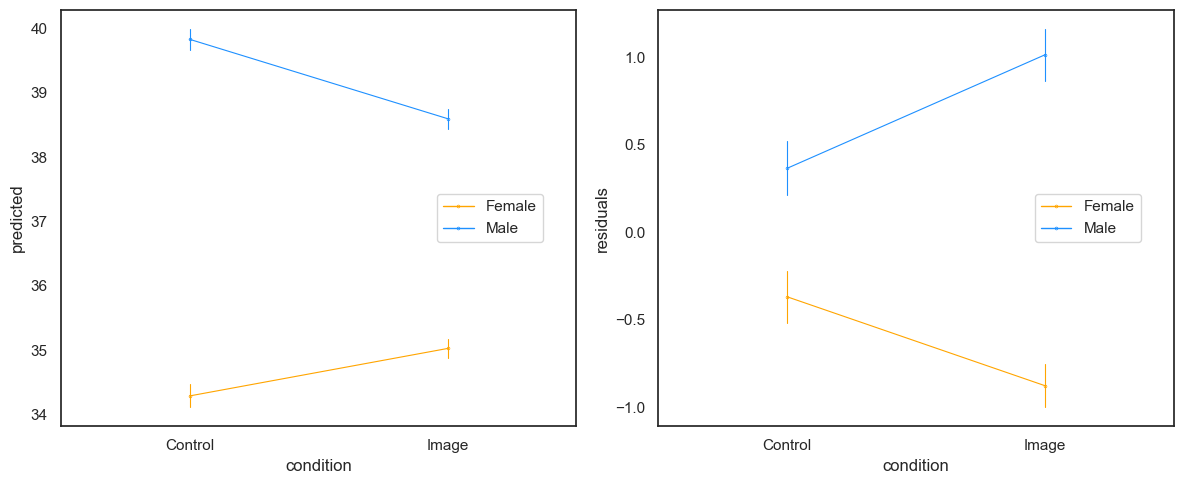

In [ ]:
# white background
sns.set_theme(style="white")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

plot_order = ["Control", "Image"]
colors = {"Female": "orange", "Male": "dodgerblue"}

# shared parameter
plot_params = {
    "data": combine,
    "x": "condition",
    "hue": "gender",
    "order": plot_order,
    "palette": colors,
    "markers": ".",       
    "markersize": 1, 
    "linestyles": "-",    
    "errorbar": ("se", 1), # vertical bars
    "native_scale": True, 
    "capsize": 0,         
}

# predicted age (plot 1)
sns.pointplot(y="age_pred", ax=ax1, **plot_params)
ax1.set_ylabel("predicted")
ax1.set_xlabel("condition")

# move legend 1 to the middle-right inside the plot
leg1 = ax1.legend(loc='center right', bbox_to_anchor=(0.95, 0.5), frameon=True)
for line in leg1.get_lines():
    line.set_linewidth(1)  # thickness

# residuals (plot 2)
sns.pointplot(y="residual", ax=ax2, **plot_params)
ax2.set_ylabel("residuals")
ax2.set_xlabel("condition")

# move legend 2 to the middle-right inside the plot
leg2 = ax2.legend(loc='center right', bbox_to_anchor=(0.95, 0.5), frameon=True)
for line in leg2.get_lines():
    line.set_linewidth(1)

# adjusting the thickness of the lines
plt.setp(ax1.lines, linewidth=0.8) 
plt.setp(ax2.lines, linewidth=0.8)

plt.tight_layout()
plt.savefig('Investigate_the_Amplification.png', dpi=300, bbox_inches='tight')
plt.show()

Explanation: 
- Age Predictions (Plot 1): The predictions in this plot are derived from the second regression model, which only included category and subj as independent variables. Because this model was not given information regarding gender or experimental condition, it lacks the 'knowledge' to reflect social stereotypes or algorithmic amplification. If the data were perfectly balanced, this should result in parallel lines where the control and treatment conditions are identical. However, due to the nature of the sampling (uneven participant distribution across groups, certain job categories appearing more frequently than others e.c.t.) the diagram shows a gap. This explains why our specific visualization appears to contradict the original paper’s findings.

- Residuals (Plot 2): This plot displays the residuals (actual - predicted).  In the Control group, a baseline bias is evident: men are generally perceived as older (positive residuals), while women are perceived as younger (negative residuals), likely driven by societal stereotypes. This bias is notably increased in the Treatment group, where the use of images causes a significant downward shift in age estimates for women compared to the control group and the upward in age estimating for the men which is caused for the amplification effect. This explains why the second diagram appears completely different from the previous one.


*Anova*

- Prepare data for ANOVA
- Specify the ANOVA model
    - dependent variable: *age*
    - independent variables: *condition*, *gender*, and their interaction
    - use sum-to-zero (Sum) contrast coding for categorical variables
- Estimate the ANOVA model

Note: Type III sums of squares are used because the model includes an interaction term, allowing each main effect and the interaction to be tested while accounting for all other terms in the model.

In [ ]:
data_anova = combine.copy()

anova_1 = smf.ols('age ~ C(condition, Sum)*C(gender, Sum)', data=data_anova).fit()
table_anova_1 = sm.stats.anova_lm(anova_1, typ=3)
# table_anova_1
display_markdown(
    table_anova_1.to_markdown(),
    raw=True
)

|                                  |           sum_sq |   df |             F |         PR(>F) |
|:---------------------------------|-----------------:|-----:|--------------:|---------------:|
| Intercept                        |      1.13998e+07 |    1 | 120337        |   0            |
| C(condition, Sum)                |     65.8665      |    1 |      0.695288 |   0.404395     |
| C(gender, Sum)                   |  71920.1         |    1 |    759.19     |   3.69217e-160 |
| C(condition, Sum):C(gender, Sum) |    347.368       |    1 |      3.66682  |   0.0555395    |
| Residual                         | 806175           | 8510 |    nan        | nan            |

Explanation:
- Condition: tests if the average age estimate changed between the Control and Image groups, with an F-statistic of 0.695 and a p-value of 0.404, this factor is not significant, meaning the experimental condition alone did not change overall age guesses
- Gender: tests for a general age difference between men and women. The extremely low p-value 3.69217e-160 ($=3.69 \times 10^{-160}$) confirms a statistically significant difference, showing that participants naturally perceive women as younger than men regardless of the condition
- Condition * Gender: tests if the "age gap" changes when images are shown, the p-value of 0.055 is just above the standard significance threshold (0.05), making it marginally significant.

- Specify the ANOVA model
    - dependent variable: *age*
    - independent variables: 
        - *condition*, *gender*, and their interaction (sum-to-zero coded)
        - *category*, *subj*
- Estimate the ANOVA model

In [ ]:
anova_2 = smf.ols('age ~ C(condition, Sum)*C(gender, Sum) + category + subj', data=data_anova).fit()
table_anova_2 = sm.stats.anova_lm(anova_2, typ=3) 
# table_anova_2
display_markdown(
    table_anova_2.to_markdown(),
    raw=True
)

|                                  |     sum_sq |   df |          F |        PR(>F) |
|:---------------------------------|-----------:|-----:|-----------:|--------------:|
| Intercept                        |  95563.8   |    1 | 2102.73    |   0           |
| C(condition, Sum)                |    615.34  |    1 |   13.5396  |   0.00023512  |
| C(gender, Sum)                   |   7053.5   |    1 |  155.201   |   2.68527e-35 |
| category                         | 230670     |   53 |   95.7644  |   0           |
| subj                             | 456023     |  453 |   22.1502  |   0           |
| C(condition, Sum):C(gender, Sum) |    329.074 |    1 |    7.24074 |   0.00714158  |
| Residual                         | 363808     | 8005 |  nan       | nan           |

Explanation: 
- Condition: the F-statistic is 13.5 and the p-value is 0.00023, this factor is highly significant and shows that moving from text to images creates a significant change in age estimates once the noise from category and subj is removed
- Gender: the extremely low p-value 2.68527e-35 ($=2.68 \times 10^{-35}$) confirms a statistically significant difference, showing that participants naturally perceive women as younger than men regardless of the condition
- category & subj: both factors have a p-value of 0, meaning they are highly significant
- Condition * Gender: the p-value of 0.007 < 0.05 and shows the statistically interaction effect

Note: By incorporating additional variables into the model, a greater proportion of the variance is explained